In [58]:
import pandas as pd
import os

# Define dataset path
dataset_path = "spotify_top_1000_tracks.csv"

# Load dataset
df = pd.read_csv(dataset_path, encoding="utf-8")

# Convert release_date and extract year
df['release_date'] = pd.to_datetime(
    df['release_date'],
    errors='coerce'
)

df['year'] = df['release_date'].dt.year

print("Dataset loaded and basic preprocessing complete!")
print(df.head(3))

Dataset loaded and basic preprocessing complete!
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9YMctZqd1...  7MXVkk9YMctZqd1Srtv4MB   
2  https://open.spotify.com/track/0TK2YIli7K1leLo...  0TK2YIli7K1leLovkQiNik   

   duration_min    year  
0      3.869767  2018.0  
1      3.840883  2016.0  
2      3.182667  2019.0  


In [59]:
import numpy as np

# Clean up text columns
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df['album'] = df['album'].str.strip()

# Convert year to integer
df['year'] = df['year'].fillna(0).astype(int)

# Drop unnecessary columns
cols_to_drop = ['spotify_url', 'id', 'release_date']

if 'time_signature' in df.columns:
    cols_to_drop.append('time_signature')

if 'key' in df.columns:
    cols_to_drop.append('key')

if 'mode' in df.columns:
    cols_to_drop.append('mode')

df = df.drop(columns=cols_to_drop, errors='ignore')

# Feature Engineering: Tempo Category
tempo_bins = [0, 100, 140, np.inf]
tempo_labels = ['Slow', 'Medium', 'Fast']

if 'tempo' in df.columns:
    df['tempo_category'] = pd.cut(
        df['tempo'],
        bins=tempo_bins,
        labels=tempo_labels,
        right=False
    )
    print("Feature 'tempo_category' created.")
else:
    print("Warning: 'tempo' column not found; skipping 'tempo_category' creation.")

# Remove duplicates
df = df.drop_duplicates(
    subset=['track_name', 'artist'],
    keep='first'
)

print("Data cleaning and feature engineering complete.")
print(f"Final Row Count after deduplication: {len(df)}")

display(df.head())

Data cleaning and feature engineering complete.
Final Row Count after deduplication: 971


,track_name,artist,album,popularity,duration_min,year
0,All The Stars (with SZA),Kendrick Lamar,Black Panther The Album Music From And Inspire...,95,3.869767,2018
1,Starboy,The Weeknd,Starboy,90,3.840883,2016
2,Señorita,Shawn Mendes,Señorita,80,3.182667,2019
3,Heat Waves,Glass Animals,Dreamland,87,3.980083,2020
4,Let Me Love You,DJ Snake,Encore,87,3.432433,2016


# HISTOGRAM

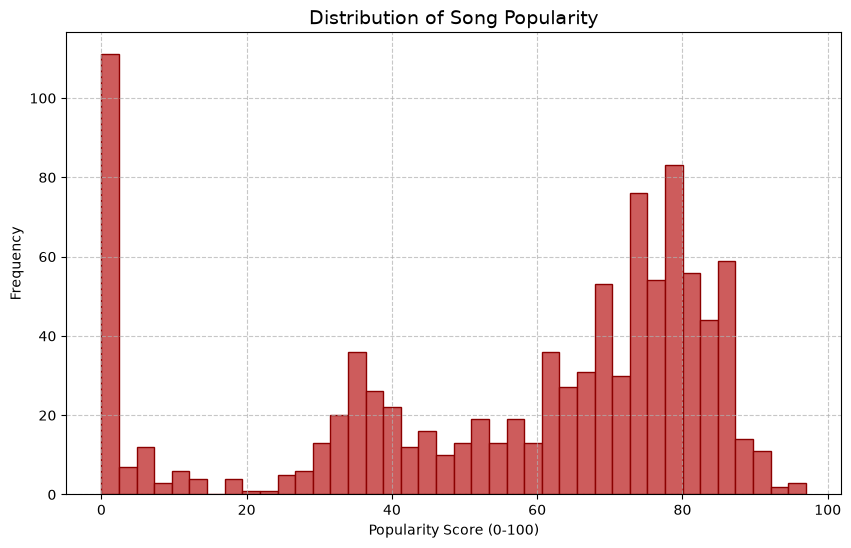

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    df['popularity'],
    bins=40,
    color='indianred',
    edgecolor='darkred'
)

plt.title('Distribution of Song Popularity', fontsize=14)
plt.xlabel('Popularity Score (0-100)')
plt.ylabel('Frequency')

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

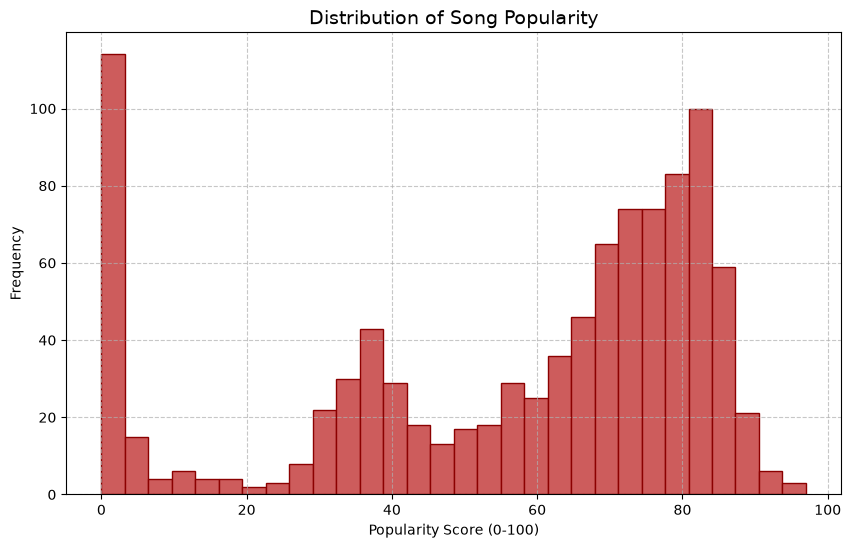

In [61]:
plt.figure(figsize=(10, 6))

plt.hist(
    df['popularity'],
    bins=30,  
    color='indianred',
    edgecolor='darkred'
)

plt.title('Distribution of Song Popularity', fontsize=14)
plt.xlabel('Popularity Score (0-100)')
plt.ylabel('Frequency')

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

# BOXPLOT

/var/folders/fb/p8v5b3yd3hl6t6tjj41z5t080000gn/T/ipykernel_42524/1795749184.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


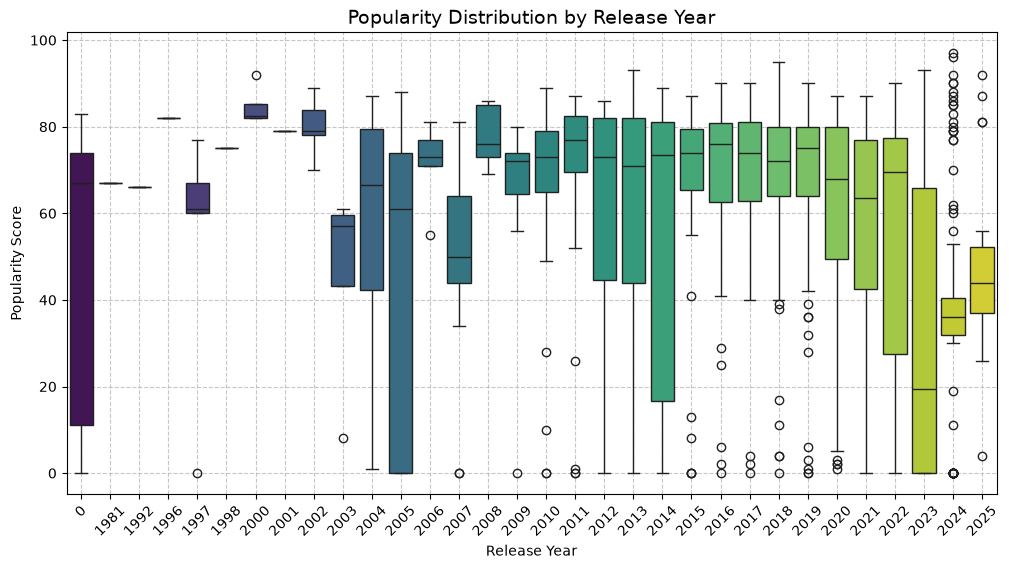

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    x='year',
    y='popularity',
    data=df,
    palette='viridis'
)

plt.title('Popularity Distribution by Release Year', fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Popularity Score')

plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

/var/folders/fb/p8v5b3yd3hl6t6tjj41z5t080000gn/T/ipykernel_42524/3250122576.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


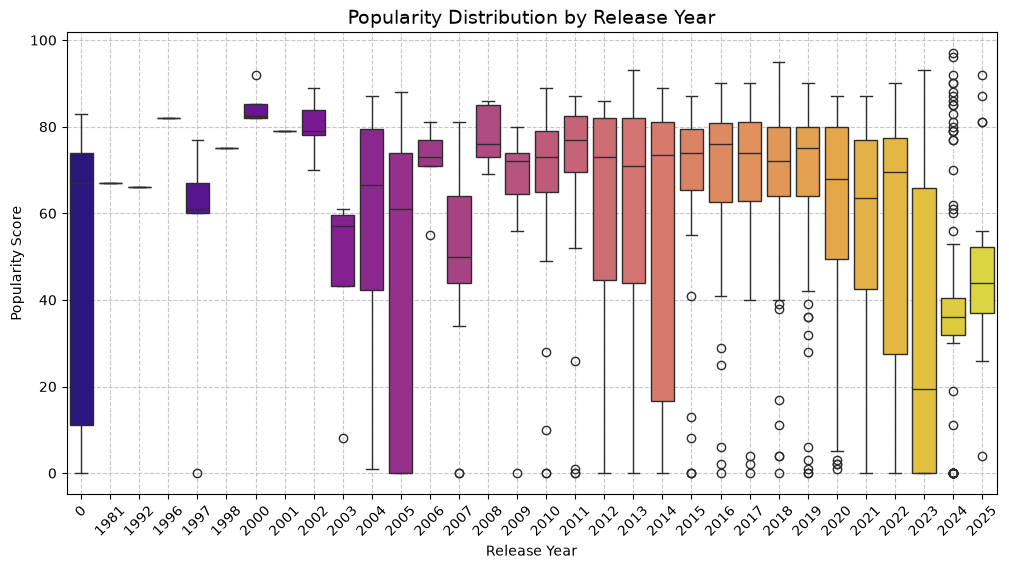

In [63]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    x='year',
    y='popularity',
    data=df,
    palette='plasma'
)

plt.title('Popularity Distribution by Release Year', fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Popularity Score')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# SCATTER PLOT

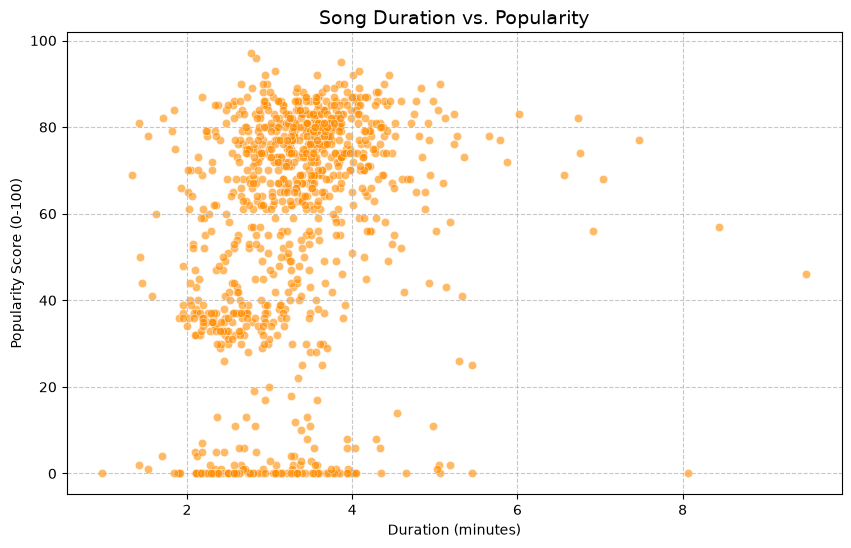

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='duration_min',
    y='popularity',
    data=df,
    alpha=0.6,
    color='darkorange'
)

plt.title('Song Duration vs. Popularity', fontsize=14)
plt.xlabel('Duration (minutes)')
plt.ylabel('Popularity Score (0-100)')
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()



In [65]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    x='duration_min',
    y='popularity',
    data=df,
    hue='artist',
    alpha=0.6
)

plt.title('Song Duration vs. Popularity by Artist', fontsize=14)
plt.xlabel('Duration (minutes)')
plt.ylabel('Popularity Score (0-100)')

plt.show()

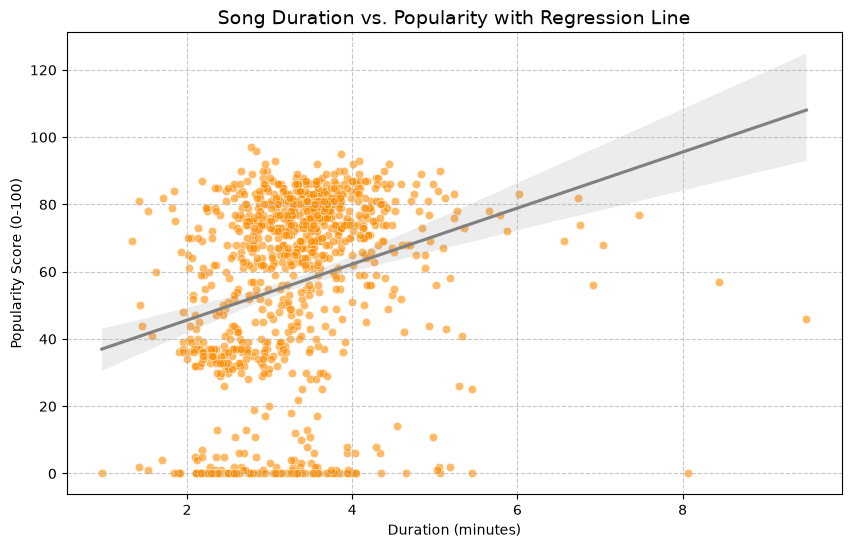

In [66]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='duration_min',
    y='popularity',
    data=df,
    alpha=0.6,
    color='darkorange'
)

sns.regplot(
    x='duration_min',
    y='popularity',
    data=df,
    scatter=False,
    color='grey'
)

plt.title('Song Duration vs. Popularity with Regression Line', fontsize=14)
plt.xlabel('Duration (minutes)')
plt.ylabel('Popularity Score (0-100)')
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

# PAIRPLOT

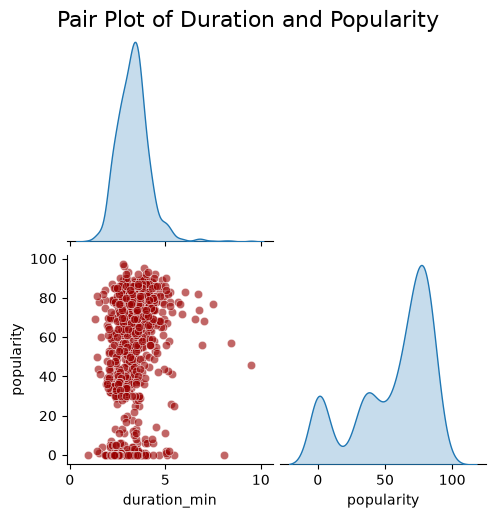

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the two numerical features
key_features = ['duration_min', 'popularity']

# Create pair plot
sns.pairplot(
    df[key_features],
    diag_kind='kde',
    corner=True,
    plot_kws={
        'alpha': 0.6,
        'color': '#990000'
    }
)

plt.suptitle(
    'Pair Plot of Duration and Popularity',
    y=1.02,
    fontsize=16
)

plt.show()

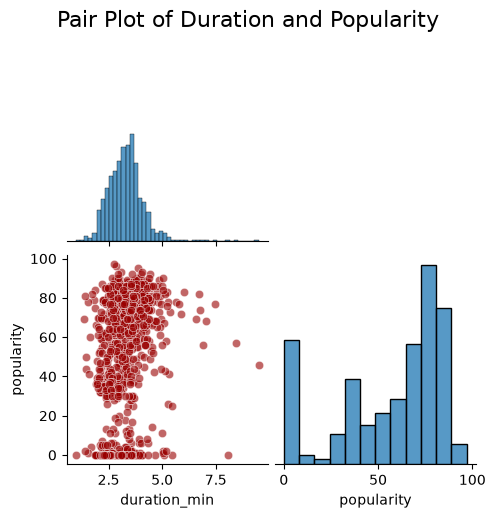

In [68]:
sns.pairplot(
    df[key_features],
    diag_kind='hist',
    corner=True,
    plot_kws={
        'alpha': 0.6,
        'color': '#990000'
    }
)

plt.suptitle(
    'Pair Plot of Duration and Popularity',
    y=1.02,
    fontsize=16
)

plt.show()

# JOINT PLOT

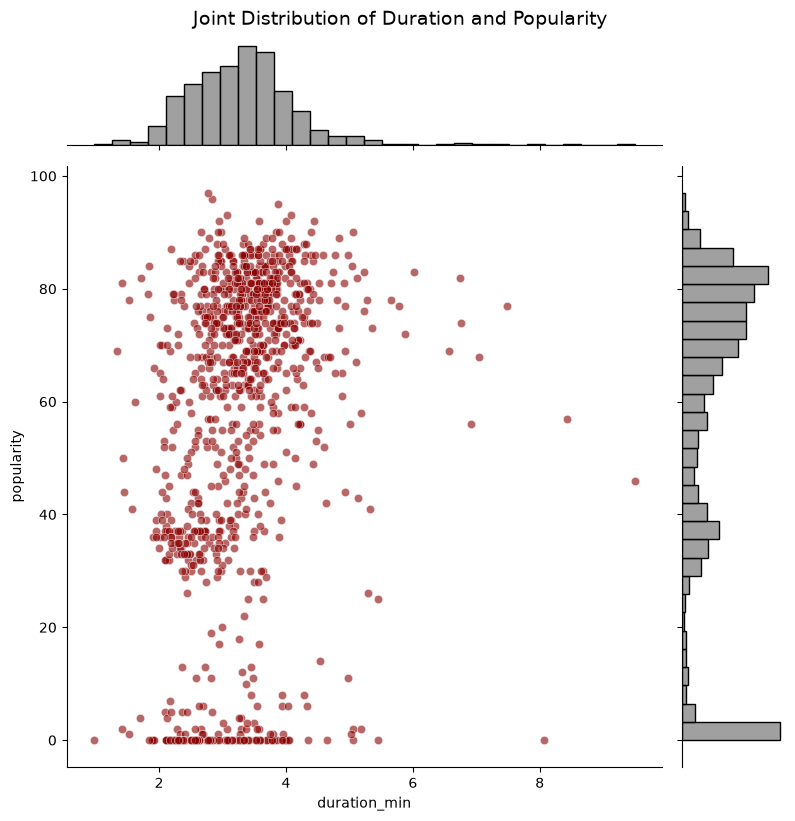

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.jointplot(
    x='duration_min',
    y='popularity',
    data=df,
    kind='scatter',
    height=8,
    marginal_kws={
        'bins': 30,
        'color': 'gray',
        'edgecolor': 'black'
    },
    joint_kws={
        'alpha': 0.6,
        'color': 'darkred'
    }
)

plt.suptitle(
    'Joint Distribution of Duration and Popularity',
    y=1.02,
    fontsize=14
)

plt.show()

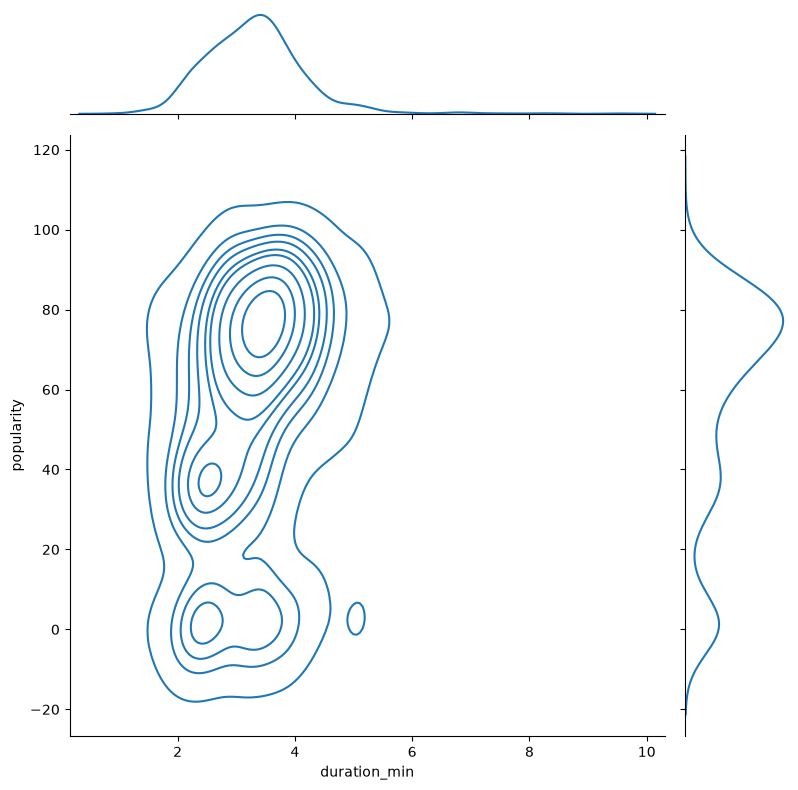

In [70]:
sns.jointplot(
    x='duration_min',
    y='popularity',
    data=df,
    kind='kde',
    height=8
)

plt.show()

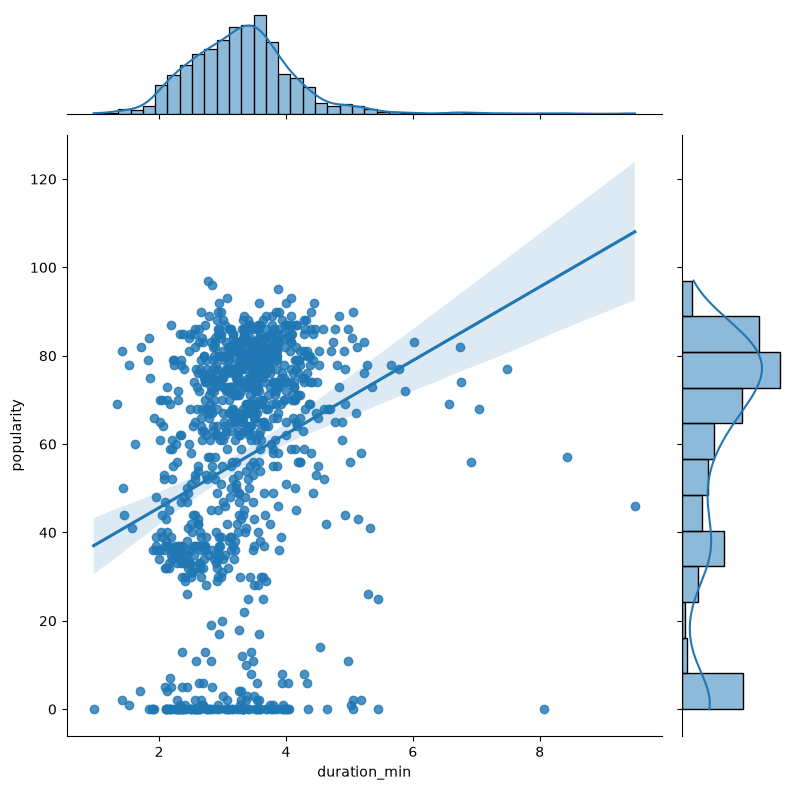

In [71]:
sns.jointplot(
    x='duration_min',
    y='popularity',
    data=df,
    kind='reg',
    height=8
)

plt.show()

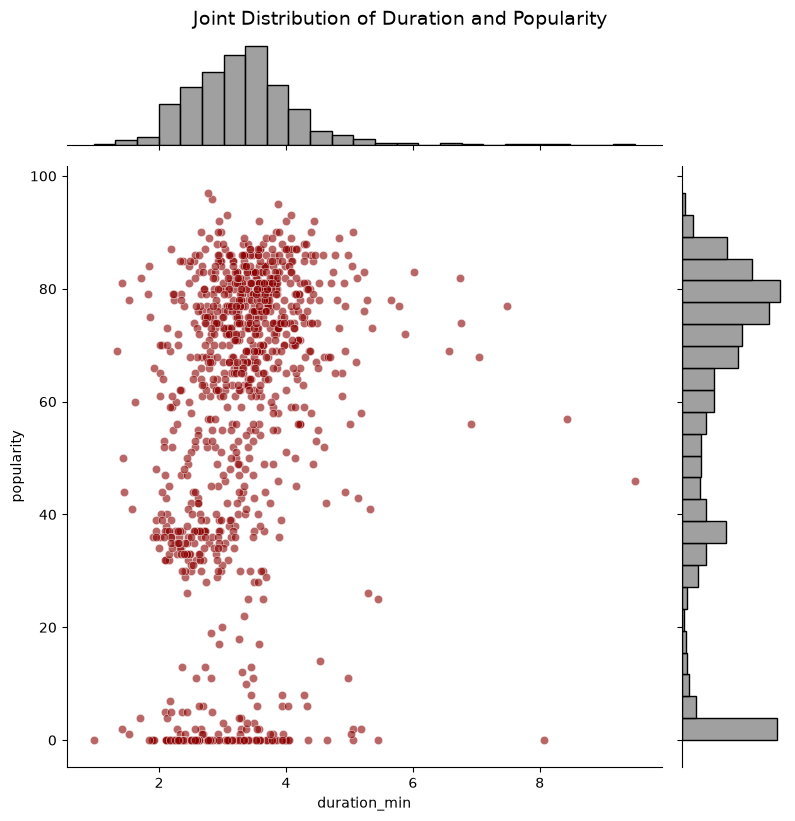

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.jointplot(
    x='duration_min',
    y='popularity',
    data=df,
    kind='scatter',
    height=8,
    marginal_kws={
        'bins': 25,
        'color': 'gray',
        'edgecolor': 'black'
    },
    joint_kws={
        'alpha': 0.6,
        'color': 'darkred'
    }
)

plt.suptitle(
    'Joint Distribution of Duration and Popularity',
    y=1.02,
    fontsize=14
)

plt.show()

In [73]:
# Requirements (install if not yet installed)
%pip install matplotlib pillow pandas

import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import webbrowser

# --- Step 1: Use the Existing Dataset ---

# Your df DataFrame is already loaded and cleaned.
# Remove records with missing or invalid release years.
animation_df = df[df['year'] != 0].copy()

# --- Step 2: Data Preparation ---

# Compute average popularity per year
yearly_popularity = (
    animation_df.groupby('year')['popularity']
    .mean()
    .reset_index()
)

yearly_popularity = yearly_popularity.sort_values('year')

print("Yearly average popularity calculated!")
display(yearly_popularity.head())

# --- Step 3: Initialize the Figure ---

fig, ax = plt.subplots(figsize=(10, 6))

ax.set_xlim(
    yearly_popularity['year'].min(),
    yearly_popularity['year'].max()
)

ax.set_ylim(
    0,
    yearly_popularity['popularity'].max() * 1.1
)

line, = ax.plot(
    [],
    [],
    color='royalblue',
    linewidth=2.5,
    label='Average Popularity'
)

ax.set_title(
    "Evolution of Track Popularity Over Time",
    fontsize=14,
    color='navy'
)

ax.set_xlabel("Year of Release", fontsize=12)
ax.set_ylabel("Average Popularity", fontsize=12)
ax.legend(loc="upper left")

plt.tight_layout()

# --- Step 4: Define Animation Function ---

def animate(i):
    x = yearly_popularity['year'].iloc[:i+1]
    y = yearly_popularity['popularity'].iloc[:i+1]

    line.set_data(x, y)

    return line,

# --- Step 5: Create and Save Animation ---

ani = FuncAnimation(
    fig,
    animate,
    frames=len(yearly_popularity),
    interval=100,
    repeat=False
)

# Automatically save the GIF
gif_path = os.path.abspath("yearly_popularity_trend.gif")

ani.save(
    gif_path,
    writer=PillowWriter(fps=10)
)

print(f"GIF saved successfully at: {gif_path}")

# --- Step 6: Open the Saved GIF ---

webbrowser.open(f"file://{gif_path}")

plt.close(fig)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Yearly average popularity calculated!


,year,popularity
0,1981,67.0
1,1992,66.0
2,1996,82.0
3,1997,53.0
4,1998,75.0


GIF saved successfully at: /Users/jherielle/Downloads/CORREA/Lab8_Data_Visualization/yearly_popularity_trend.gif


In [74]:
# Requirements
%pip install matplotlib pillow pandas

import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import webbrowser

# --- Step 1: Use the Existing Dataset ---

animation_df = df[df['year'] != 0].copy()

# --- Step 2: Data Preparation ---

# Compute average popularity per year
yearly_popularity = (
    animation_df.groupby('year')['popularity']
    .mean()
    .reset_index()
)

yearly_popularity = yearly_popularity.sort_values('year')

print("Yearly average popularity calculated!")
display(yearly_popularity.head())

# --- Step 3: Initialize the Figure ---

fig, ax = plt.subplots(figsize=(10, 6))

ax.set_xlim(
    yearly_popularity['year'].min(),
    yearly_popularity['year'].max()
)

ax.set_ylim(
    0,
    yearly_popularity['popularity'].max() * 1.1
)

line, = ax.plot(
    [],
    [],
    color='royalblue',
    linewidth=2.5,
    label='Average Popularity'
)

ax.set_title(
    "Evolution of Track Popularity Over Time",
    fontsize=14,
    color='navy'
)

ax.set_xlabel("Year of Release", fontsize=12)
ax.set_ylabel("Average Popularity", fontsize=12)
ax.legend(loc="upper left")

plt.tight_layout()

# --- Step 4: Define Animation Function ---

def animate(i):
    x = yearly_popularity['year'].iloc[:i+1]
    y = yearly_popularity['popularity'].iloc[:i+1]

    line.set_data(x, y)

    return line,

# --- Step 5: Create and Save Animation ---

ani = FuncAnimation(
    fig,
    animate,
    frames=len(yearly_popularity),
    interval=60,  # Changed from 100 to 60
    repeat=False
)

# Automatically save the GIF
gif_path = os.path.abspath("yearly_popularity_trend.gif")

ani.save(
    gif_path,
    writer=PillowWriter(fps=10)
)

print(f"GIF saved successfully at: {gif_path}")

# --- Step 6: Open the Saved GIF ---

webbrowser.open(f"file://{gif_path}")

plt.close(fig)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Yearly average popularity calculated!


,year,popularity
0,1981,67.0
1,1992,66.0
2,1996,82.0
3,1997,53.0
4,1998,75.0


GIF saved successfully at: /Users/jherielle/Downloads/CORREA/Lab8_Data_Visualization/yearly_popularity_trend.gif


# IV. DATA AND OBSERVATION

In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load the original dataset
dataset_path = "spotify_top_1000_tracks.csv"

df = pd.read_csv(dataset_path, encoding="utf-8")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   
3                Heat Waves   Glass Animals   
4           Let Me Love You        DJ Snake   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   
3                                          Dreamland   2020-08-07          87   
4                                             Encore   2016-08-05          87   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9

In [76]:
student_name = "Correa"
student_id = "TUPM-26-1106"

id_num = int(student_id[-3:])

color1 = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"

color2 = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"

print("Color 1:", color1)
print("Color 2:", color2)

Color 1: #e63e12
Color 2: #d4baa8


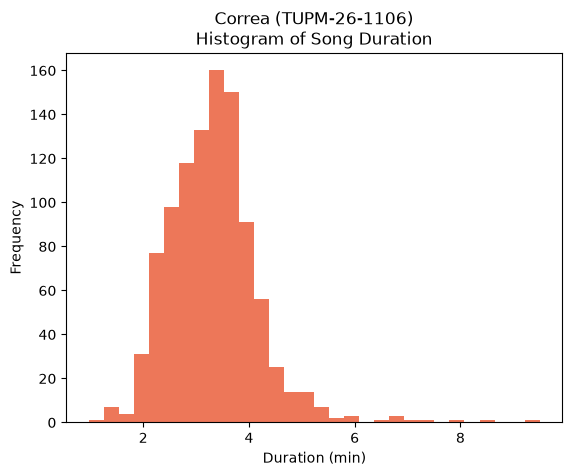

In [77]:
df['duration_min'].plot(
    kind='hist',
    bins=30,
    color=color1,
    alpha=0.7
)

plt.title(
    f"{student_name} ({student_id})\nHistogram of Song Duration"
)

plt.xlabel('Duration (min)')
plt.ylabel('Frequency')

plt.show()

/var/folders/fb/p8v5b3yd3hl6t6tjj41z5t080000gn/T/ipykernel_42524/933493804.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='decade', y='popularity', data=df, palette='coolwarm')


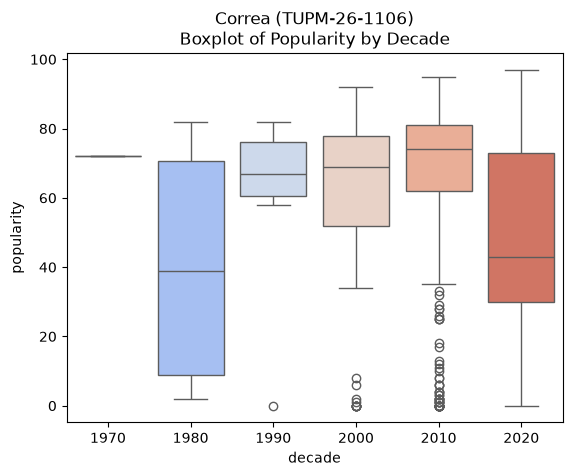

In [78]:
df['release_year'] = pd.to_datetime(
    df['release_date'],
    format='mixed',
    errors='coerce'
).dt.year

df['decade'] = (df['release_year'] // 10) * 10

sns.boxplot(x='decade', y='popularity', data=df, palette='coolwarm')

plt.title(f"{student_name} ({student_id})\nBoxplot of Popularity by Decade")

plt.show()

/var/folders/fb/p8v5b3yd3hl6t6tjj41z5t080000gn/T/ipykernel_42524/3663548020.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


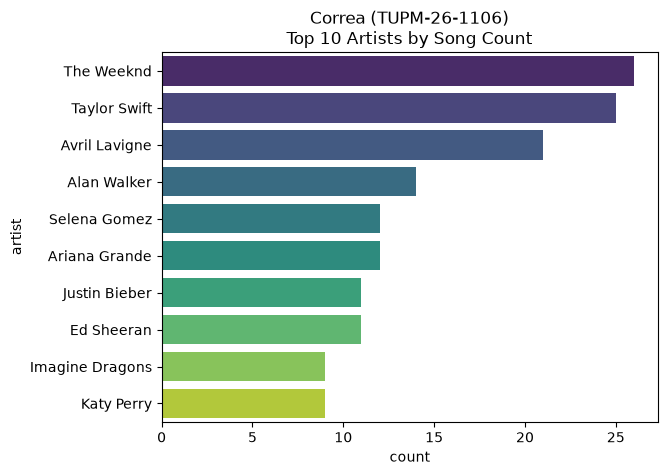

In [79]:
sns.countplot(
    y='artist',
    data=df,
    order=df['artist'].value_counts().head(10).index,
    palette='viridis'
)

plt.title(f"{student_name} ({student_id})\nTop 10 Artists by Song Count")

plt.show()

/var/folders/fb/p8v5b3yd3hl6t6tjj41z5t080000gn/T/ipykernel_42524/417253127.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/fb/p8v5b3yd3hl6t6tjj41z5t080000gn/T/ipykernel_42524/417253127.py:1: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


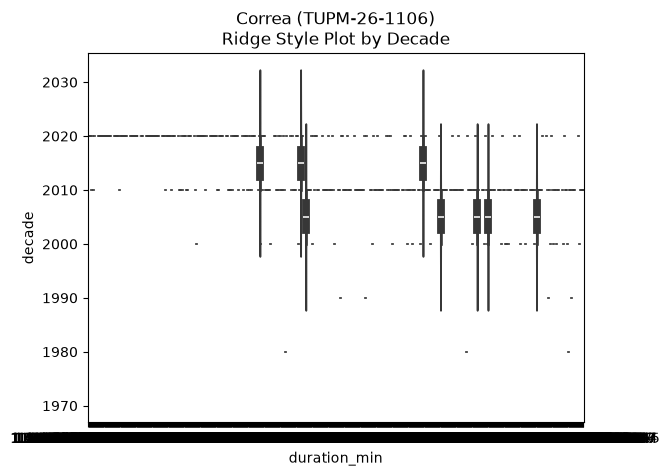

In [80]:
sns.violinplot(
    data=df,
    x='duration_min',
    y='decade',
    palette='coolwarm',
    scale='width'
)

plt.title(f"{student_name} ({student_id})\nRidge Style Plot by Decade")

plt.show()

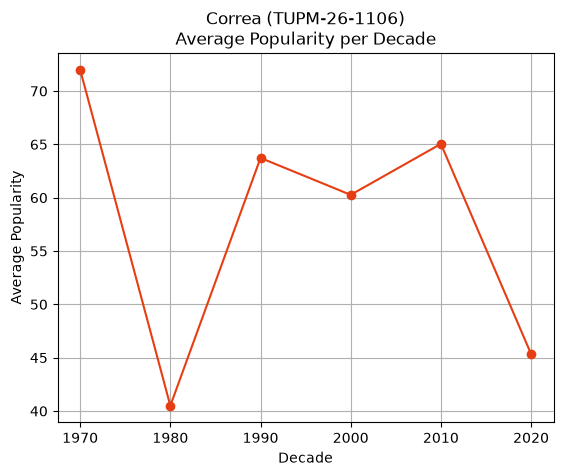

In [81]:
avg_pop = df.groupby('decade')['popularity'].mean()

avg_pop.plot(kind='line', color=color1, marker='o')

plt.title(f"{student_name} ({student_id})\nAverage Popularity per Decade")

plt.xlabel('Decade')
plt.ylabel('Average Popularity')

plt.grid(True)

plt.show()

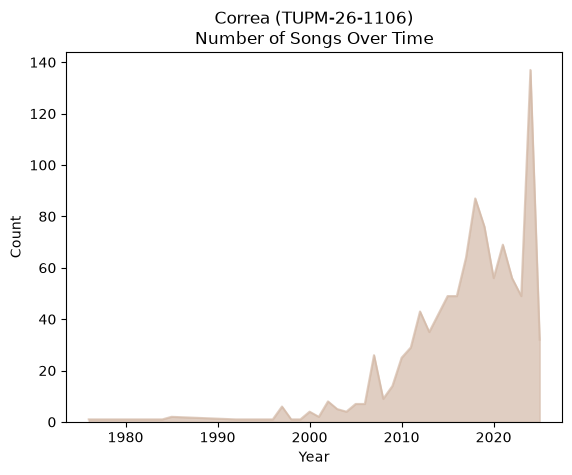

In [82]:
df['release_year'] = pd.to_datetime(
    df['release_date'],
    errors='coerce',
    format='mixed'
).dt.year

count_by_year = df['release_year'].value_counts().sort_index()

count_by_year.plot(kind='area', color=color2, alpha=0.7)

plt.title(f"{student_name} ({student_id})\nNumber of Songs Over Time")

plt.xlabel('Year')
plt.ylabel('Count')

plt.show()

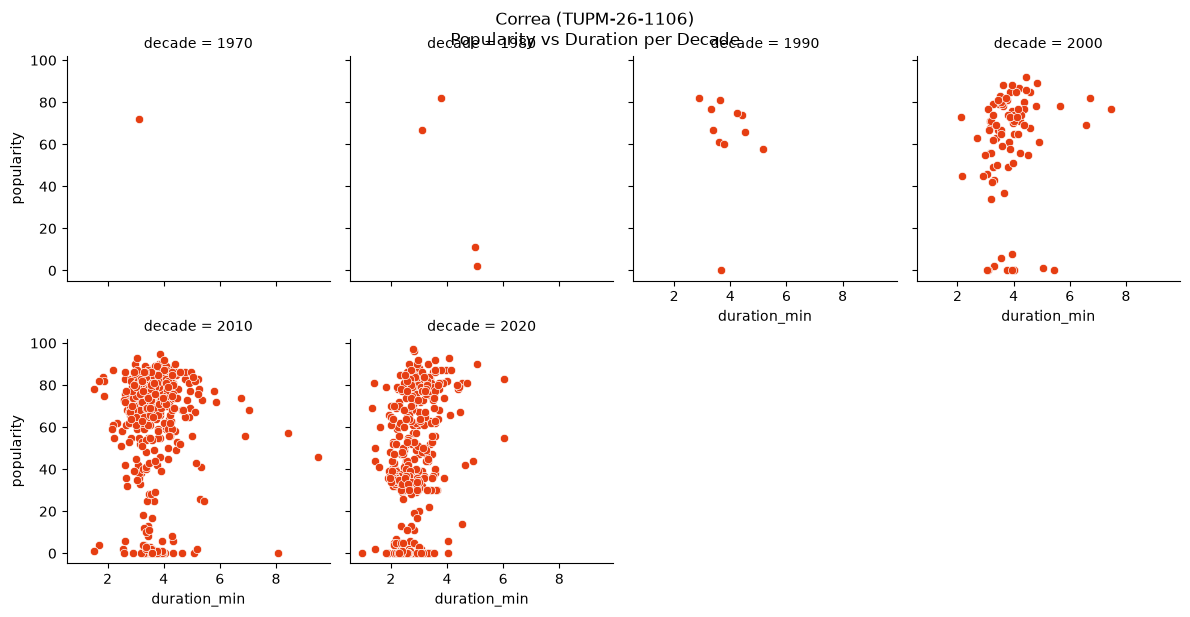

In [83]:
g = sns.FacetGrid(df, col='decade', col_wrap=4, height=3)

g.map_dataframe(
    sns.scatterplot,
    x='duration_min',
    y='popularity',
    color=color1
)

g.fig.suptitle(
    f"{student_name} ({student_id})\nPopularity vs Duration per Decade",
    y=1.02
)

plt.show()

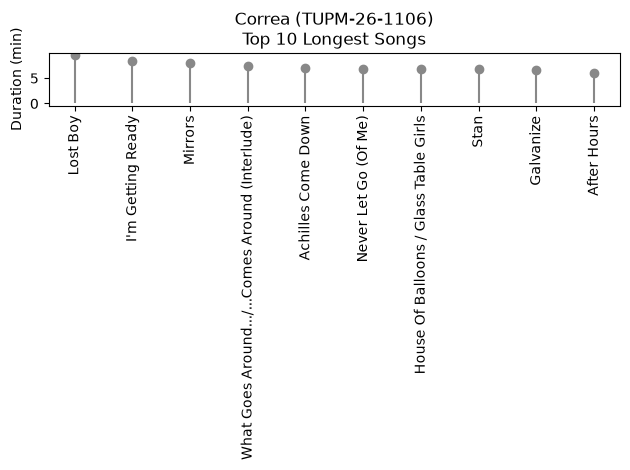

In [84]:
longest = df.nlargest(10, 'duration_min')

plt.stem(
    longest['track_name'],
    longest['duration_min'],
    linefmt='#888888',
    markerfmt='o',
    basefmt=" "
)

plt.xticks(rotation=90)

plt.title(f"{student_name} ({student_id})\nTop 10 Longest Songs")

plt.ylabel('Duration (min)')

plt.tight_layout()

plt.show()

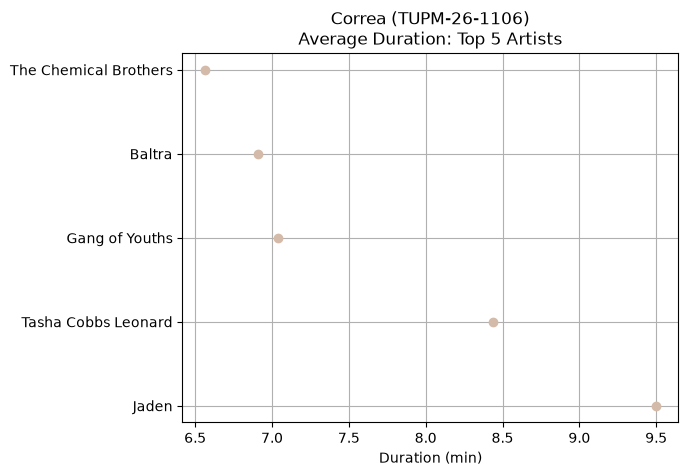

In [85]:
avg_duration = df.groupby('artist')['duration_min'].mean().nlargest(5)

plt.plot(avg_duration.values, avg_duration.index, 'o', color=color2)

plt.title(f"{student_name} ({student_id})\nAverage Duration: Top 5 Artists")

plt.xlabel('Duration (min)')

plt.grid(True)

plt.show()

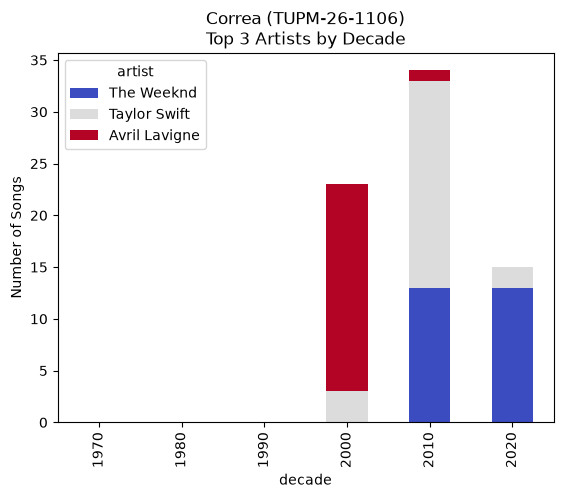

In [86]:
crosstab = pd.crosstab(df['decade'], df['artist'])

top3 = df['artist'].value_counts().head(3).index

crosstab[top3].plot(kind='bar', stacked=True, colormap='coolwarm')

plt.title(f"{student_name} ({student_id})\nTop 3 Artists by Decade")

plt.ylabel('Number of Songs')

plt.show()

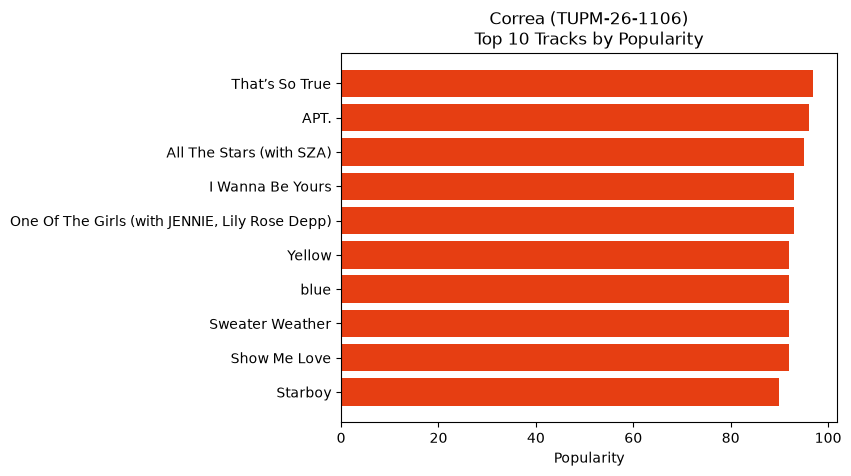

In [87]:
top_tracks = df.nlargest(10, 'popularity')

plt.barh(top_tracks['track_name'], top_tracks['popularity'], color=color1)

plt.xlabel('Popularity')

plt.title(f"{student_name} ({student_id})\nTop 10 Tracks by Popularity")

plt.gca().invert_yaxis()

plt.show()

/var/folders/fb/p8v5b3yd3hl6t6tjj41z5t080000gn/T/ipykernel_42524/566981994.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/fb/p8v5b3yd3hl6t6tjj41z5t080000gn/T/ipykernel_42524/566981994.py:3: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.stripplot(


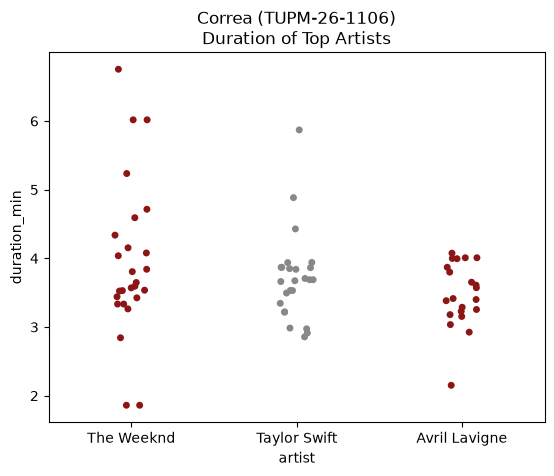

In [88]:
top_artists = df['artist'].value_counts().head(3).index

sns.stripplot(
    data=df[df['artist'].isin(top_artists)],
    x='artist',
    y='duration_min',
    palette=['#8C1515', '#888888']
)

plt.title(f"{student_name} ({student_id})\nDuration of Top Artists")

plt.show()

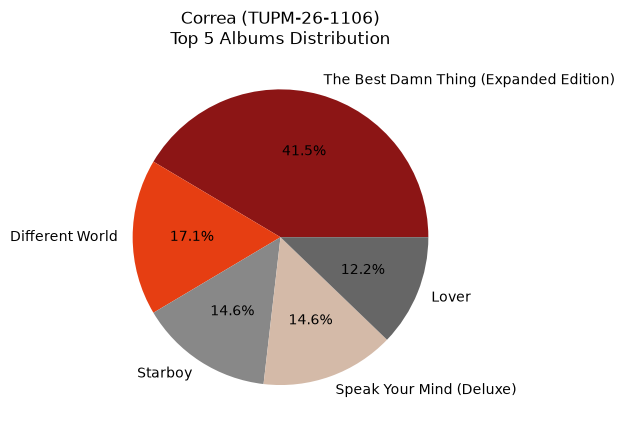

In [89]:
top_albums = df['album'].value_counts().head(5)
colors = ['#8C1515', color1, '#888888', color2, '#666666']
plt.pie(top_albums, labels=top_albums.index, autopct='%1.1f%%',
colors=colors)
plt.title(f"{student_name} ({student_id})\nTop 5 Albums Distribution")
plt.show()

In [90]:
%pip install scipy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


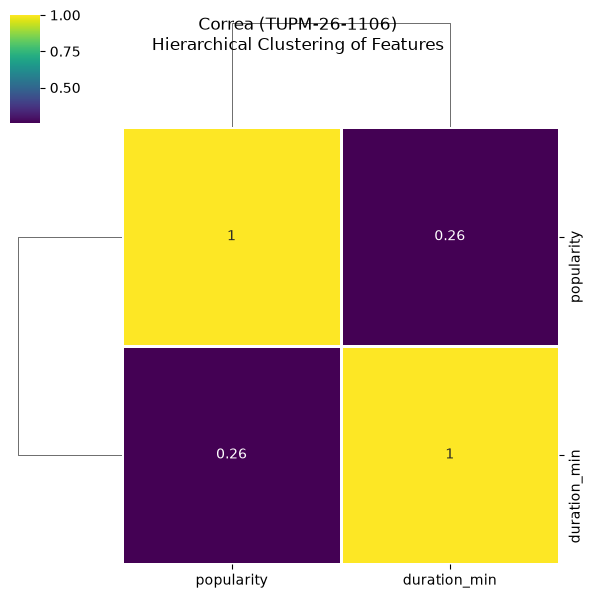

In [91]:
numerical_cols = ['popularity', 'duration_min']

df_numeric = df[numerical_cols].dropna()

sns.clustermap(
    df_numeric.corr(),
    annot=True,
    cmap='viridis',
    linewidths=.75,
    figsize=(6, 6)
)

plt.suptitle(f"{student_name} ({student_id})\nHierarchical Clustering of Features")

plt.show()

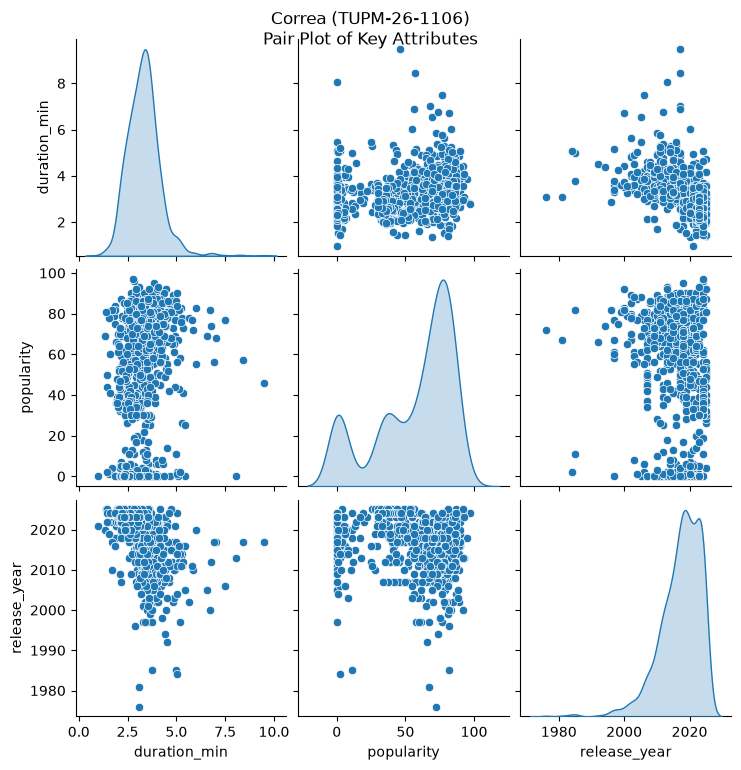

In [92]:
sns.pairplot(
    df[['duration_min', 'popularity', 'release_year']],
    diag_kind='kde'
)

plt.suptitle(
    f"{student_name} ({student_id})\nPair Plot of Key Attributes",
    y=1.02
)

plt.show()

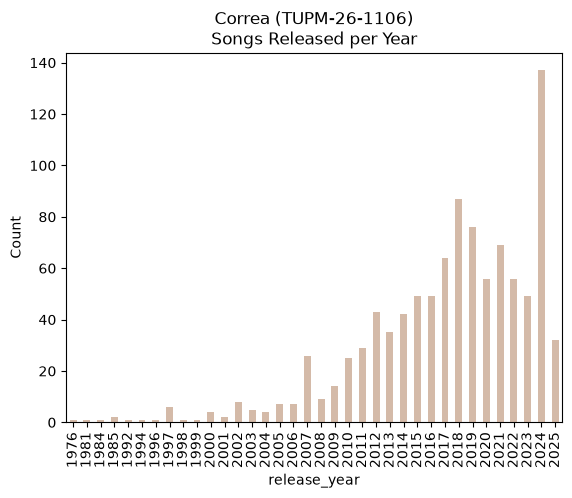

In [93]:
df['release_year'].value_counts().sort_index().plot(
    kind='bar',
    color=color2
)

plt.title(f"{student_name} ({student_id})\nSongs Released per Year")

plt.ylabel('Count')

plt.show()

/var/folders/fb/p8v5b3yd3hl6t6tjj41z5t080000gn/T/ipykernel_42524/4247256220.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


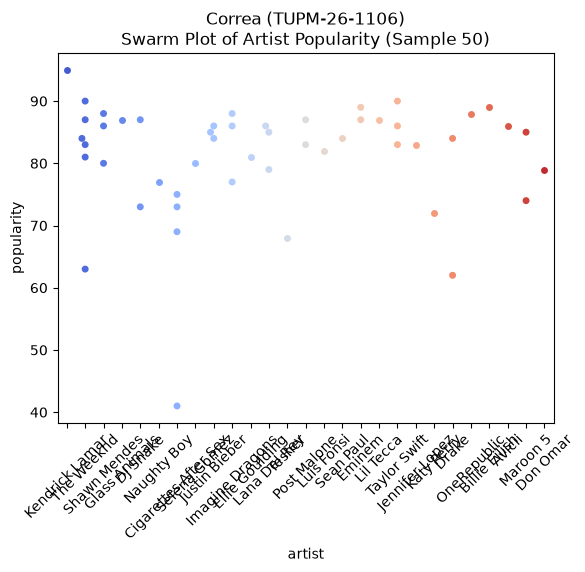

In [94]:
sns.swarmplot(
    data=df.head(50),
    x='artist',
    y='popularity',
    palette='coolwarm'
)

plt.title(
    f"{student_name} ({student_id})\nSwarm Plot of Artist Popularity (Sample 50)"
)

plt.xticks(rotation=45)

plt.show()

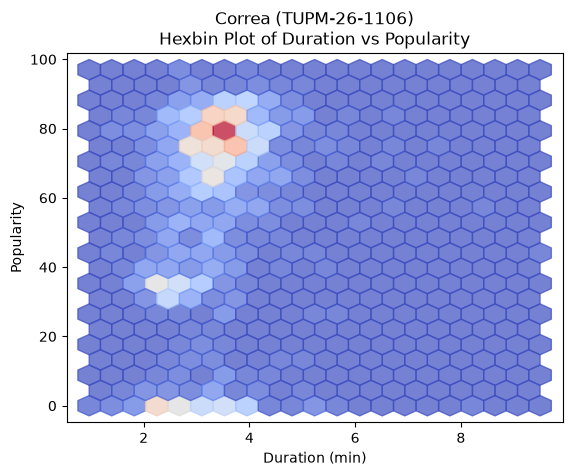

In [95]:
plt.hexbin(
    df['duration_min'],
    df['popularity'],
    gridsize=20,
    cmap='coolwarm',
    alpha=0.7
)

plt.xlabel('Duration (min)')
plt.ylabel('Popularity')

plt.title(
    f"{student_name} ({student_id})\nHexbin Plot of Duration vs Popularity"
)

plt.show()

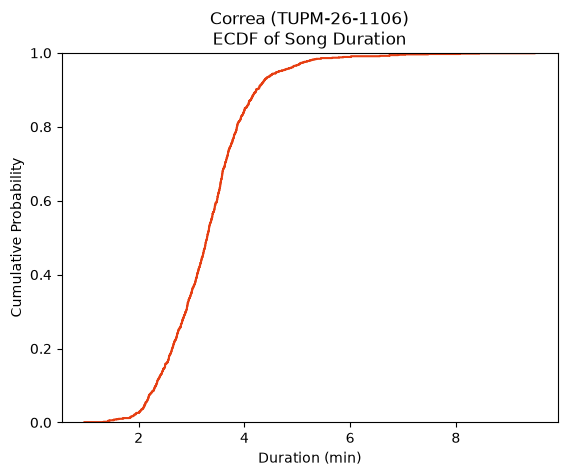

In [96]:
sns.ecdfplot(data=df, x='duration_min', color=color1)

plt.title(f"{student_name} ({student_id})\nECDF of Song Duration")

plt.xlabel('Duration (min)')
plt.ylabel('Cumulative Probability')

plt.show()

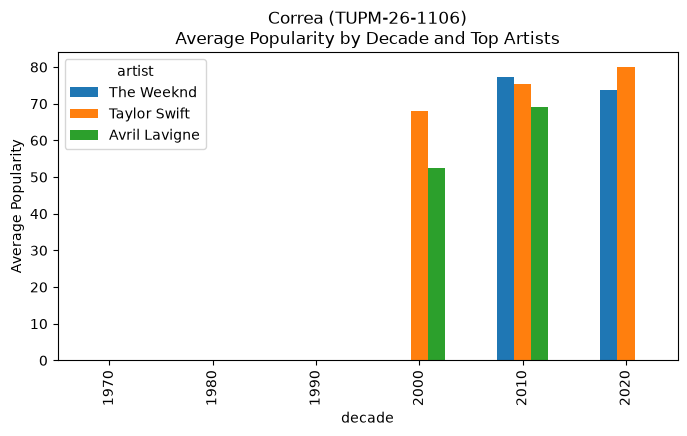

In [97]:
avg_artist_decade = df.groupby(
    ['decade', 'artist']
)['popularity'].mean().unstack().fillna(0)

avg_artist_decade[top3].plot(kind='bar', figsize=(8, 4))

plt.title(
    f"{student_name} ({student_id})\nAverage Popularity by Decade and Top Artists"
)

plt.ylabel('Average Popularity')

plt.show()